In [2]:
import anndata
from anndata import AnnData
import pandas as pd
import rectanglepy as rp
import matplotlib.pyplot as plt
from scipy.io import mmread
from scipy.sparse import csr_matrix
import helper

import re



# Figure 4

## Figure 4A


Load the data

In [28]:
gld = pd.read_excel("../data/fig4/luca_cancer.xlsx", index_col=0)
gld = gld.fillna(0)
gld = gld[gld["Cancer type"] == "BRCA"]

gld = gld.drop(columns=["Unnamed: 7", "Cancer type"])
gld.index = gld.index.str.replace("-", ".")
# Create a new column 'sample_name' that contains the sample names without the last character
gld['sample_name'] = gld.index.str[:-1]

# Group the rows based on the 'sample_name' column and calculate the mean for each group
df_grouped = gld.groupby('sample_name').mean()

/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


### Brca data

In [5]:
annotations_brca = pd.read_csv("../data/fig4/brca_nocycling_annotations.csv", index_col=0)
sc_data_brca = pd.read_csv("../data/fig4/brca_nocycline_counts.csv", index_col=0)
bulks_brca = pd.read_csv("../data/fig4/TCGA_tpm_BRCA.txt", sep="\t")

ribsosomal_gene_re = r"^RP[SL]|^RP\d|^RPSA"
# remove ribosomal genes from bulk and scRNA-seq data
sc_data_brca = sc_data_brca[~sc_data_brca.index.str.match(ribsosomal_gene_re)]
bulks_brca = bulks_brca[~bulks_brca.index.str.match(ribsosomal_gene_re)]


annotations_brca.index = sc_data_brca.columns
annotations = pd.Series(annotations_brca["x"])

adata_brca = AnnData(sc_data_brca.T, obs=annotations.to_frame(name="cell_type"))
adata_brca = adata_brca[adata_brca.obs['cell_type'] != 'Normal Epithelial']
adata_brca_no_cancer = adata_brca[adata_brca.obs['cell_type'] != 'Cancer Epithelial']


In [ ]:
# rsults with cancer ce
brca_estimations, signature_results_brca = rp.rectangle(adata_brca, bulks_brca.T)
brca_estimations.to_csv("../output/brca_estimations.csv")


In [ ]:
brca_estimations_no_cancer, signature_results_brca_no_cancer = rp.rectangle(adata_brca_no_cancer, bulks_brca.T)
brca_estimations_no_cancer.to_csv("../output/brca_estimations_no_cancer.csv")

In [18]:
# Unknown  and Cancer Epithelial
brca_estimations = pd.read_csv("../output/brca_estimations.csv", index_col=0)
brca_estimations.index = brca_estimations.index.str.replace("-", ".")
brca_estimations['CPE'] = brca_estimations['Unknown'] + brca_estimations['Cancer Epithelial']
brca_estimations_m, gld_m = helper.match_dfs(brca_estimations, df_grouped)
evaluation_brca = helper.create_evaluation_df(gld_m.T, brca_estimations_m.T)
rsme_brca, r_brca, p_brca= helper.evaulate_total_df(evaluation_brca)

# Just Cancer
brca_estimations = pd.read_csv("../output/brca_estimations.csv", index_col=0)
brca_estimations.index = brca_estimations.index.str.replace("-", ".")
brca_estimations['CPE'] = brca_estimations['Cancer Epithelial']
brca_estimations_m, gld_m_cancer = helper.match_dfs(brca_estimations, df_grouped)
evaluation_brca_cancer = helper.create_evaluation_df(gld_m_cancer.T, brca_estimations_m.T)
rsme_brca_cancer, r_brca_cancer, p_brca = helper.evaulate_total_df(evaluation_brca_cancer)

# Just Unkwnown
brca_estimations_no_cancer = pd.read_csv("../output/brca_estimations_no_cancer.csv", index_col=0)
brca_estimations_no_cancer.index = brca_estimations_no_cancer.index.str.replace("-", ".")
brca_estimations_no_cancer['CPE'] =  brca_estimations_no_cancer['Unknown']
brca_estimations_no_cancer_m, gld_m_no_cancer = helper.match_dfs(brca_estimations_no_cancer, df_grouped)
evaluation_brca_no_cancer = helper.create_evaluation_df(gld_m_no_cancer.T, brca_estimations_no_cancer_m.T)
rsme_brca_no_cancer, r_brca_no_cancer, p_brca_no_cancer = helper.evaulate_total_df(evaluation_brca_no_cancer)

### Luad + Lusc data

In [31]:
gld = pd.read_excel("../data/fig4/luca_cancer.xlsx", index_col=0)
gld = gld.fillna(0)
gld = gld.drop(columns=["Unnamed: 7", "Cancer type"])
gld.index = gld.index.str.replace("-", ".")
# Create a new column 'sample_name' that contains the sample names without the last character
gld['sample_name'] = gld.index.str[:-1]

# Group the rows based on the 'sample_name' column and calculate the mean for each group
df_grouped = gld.groupby('sample_name').mean()


gld.to_csv("./luca_gld.csv")

/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


In [23]:
luad_bulk = pd.read_csv("../data/fig4/luad.csv", index_col=0)
lusc_bulk = pd.read_csv("../data/fig4/lusc.csv", index_col=0)

luca_sd = anndata.read_h5ad("../data/fig4/lambrechts.h5ad")
luca_sd = luca_sd[luca_sd.obs['cell_type'] != 'Epithelial cells']
luca_sd_no_cancer = luca_sd[luca_sd.obs['cell_type'] != 'Tumor cells']

# remove ribosomal genes from bulk is enough since rectangle matches the genes
ribsosomal_gene_re = r"^RP[SL]|^RP\d|^RPSA"
luad_bulk = luad_bulk[~luad_bulk.index.str.match(ribsosomal_gene_re)]
lusc_bulk = lusc_bulk[~lusc_bulk.index.str.match(ribsosomal_gene_re)]


In [ ]:
luad_estimations, signature_results_luad = rp.rectangle(luca_sd, luad_bulk.T)
luad_estimations.to_csv("../output/luad_estimations.csv")

lusc_estimations, signature_results_lusc = rp.rectangle(luca_sd, lusc_bulk.T)
lusc_estimations.to_csv("../output/lusc_estimations.csv")

In [ ]:
luad_estimations_no_cancer, signature_results_luad_no_cancer = rp.rectangle(luca_sd_no_cancer, luad_bulk.T)
luad_estimations_no_cancer.to_csv("../output/luad_estimations_no_cancer.csv")
lusc_estimations_no_cancer, signature_results_lusc_no_cancer = rp.rectangle(luca_sd_no_cancer, lusc_bulk.T)
lusc_estimations_no_cancer.to_csv("../output/lusc_estimations_no_cancer.csv")

In [33]:
luad_estimations = pd.read_csv("../output/luad_estimations.csv", index_col=0)
luad_estimations['CPE'] = luad_estimations['Unknown'] + luad_estimations['Tumor cells']
luad_estimations_m, luad_gld_m = helper.match_dfs(luad_estimations, df_grouped)
evaluation_luad = helper.create_evaluation_df(luad_gld_m.T, luad_estimations_m.T)
rsme_luad, r_luad, p_luad = helper.evaulate_total_df(evaluation_luad)

# Just Tumor cells
luad_estimations = pd.read_csv("../output/luad_estimations.csv", index_col
=0)
luad_estimations['CPE'] = luad_estimations['Tumor cells']
luad_estimations_m, luad_gld_m_cancer = helper.match_dfs(luad_estimations, df_grouped)
evaluation_luad_cancer = helper.create_evaluation_df(luad_gld_m_cancer.T, luad_estimations_m.T)
rsme_luad_cancer, r_luad_cancer, p_luad = helper.evaulate_total_df(evaluation_luad_cancer)

# Just Unknown
luad_estimations_no_cancer = pd.read_csv("../output/luad_estimations_no_cancer.csv", index_col=0)
luad_estimations_no_cancer['CPE'] = luad_estimations_no_cancer['Unknown']
luad_estimations_no_cancer_m, luad_gld_m_no_cancer = helper.match_dfs(luad_estimations_no_cancer, df_grouped)
evaluation_luad_no_cancer = helper.create_evaluation_df(luad_gld_m_no_cancer.T, luad_estimations_no_cancer_m.T)
rsme_luad_no_cancer, r_luad_no_cancer, p_luad_no_cancer = helper.evaulate_total_df(evaluation_luad_no_cancer)

# LUSC: Unknown + Tumor cells
lusc_estimations = pd.read_csv("../output/lusc_estimations.csv", index_col=0)
lusc_estimations['CPE'] = lusc_estimations['Unknown'] + lusc_estimations['Tumor cells']
lusc_estimations_m, lusc_gld_m = helper.match_dfs(lusc_estimations, df_grouped)
evaluation_lusc = helper.create_evaluation_df(lusc_gld_m.T, lusc_estimations_m.T)
rsme_lusc, r_lusc, p_lusc = helper.evaulate_total_df(evaluation_lusc)

# LUSC: Just Tumor cells
lusc_estimations = pd.read_csv("../output/lusc_estimations.csv", index_col=0)
lusc_estimations['CPE'] = lusc_estimations['Tumor cells']
lusc_estimations_m, lusc_gld_m_cancer = helper.match_dfs(lusc_estimations, df_grouped)
evaluation_lusc_cancer = helper.create_evaluation_df(lusc_gld_m_cancer.T, lusc_estimations_m.T)
rsme_lusc_cancer, r_lusc_cancer, p_lusc = helper.evaulate_total_df(evaluation_lusc_cancer)

# LUSC: Just Unknown
lusc_estimations_no_cancer = pd.read_csv("../output/lusc_estimations_no_cancer.csv", index_col=0)
lusc_estimations_no_cancer['CPE'] = lusc_estimations_no_cancer['Unknown']
lusc_estimations_no_cancer_m, lusc_gld_m_no_cancer = helper.match_dfs(lusc_estimations_no_cancer, df_grouped)
evaluation_lusc_no_cancer = helper.create_evaluation_df(lusc_gld_m_no_cancer.T, lusc_estimations_no_cancer_m.T)
rsme_lusc_no_cancer, r_lusc_no_cancer, p_lusc_no_cancer = helper.evaulate_total_df(evaluation_lusc_no_cancer)





<Axes: title={'center': 'Tumor+Unkn'}, xlabel='Tumor purity', ylabel='Tumor + unknown cells'>

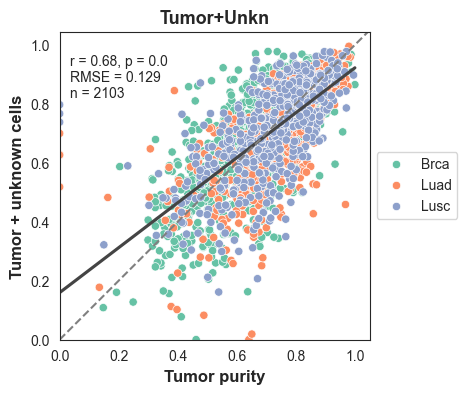

In [37]:

luad_estimations = pd.read_csv("../output/luad_estimations.csv", index_col=0)
luad_estimations['CPE'] = luad_estimations['Unknown'] + luad_estimations['Tumor cells']

lusc_estimations = pd.read_csv("../output/lusc_estimations.csv", index_col=0)
lusc_estimations['CPE'] = lusc_estimations['Unknown'] + lusc_estimations['Tumor cells']

brca_estimations = pd.read_csv("../output/brca_estimations.csv", index_col=0)
brca_estimations.index = brca_estimations.index.str.replace("-", ".")
brca_estimations['CPE'] = brca_estimations['Unknown'] + brca_estimations['Cancer Epithelial']


luad_estimations['data'] = 'Luad'
lusc_estimations['data'] = 'Lusc'
brca_estimations['data'] = 'Brca'

all = pd.concat([brca_estimations, luad_estimations, lusc_estimations])

all_m, gld_m = helper.match_dfs(all, df_grouped)

evaluation_all = helper.create_evaluation_df(gld_m.T, all_m.T)

evaluation_all['data'] = list(all['data'])

rsme_all, r_all, p_all = helper.evaulate_total_df(evaluation_all)

helper.create_scatter_plot_total(evaluation_all, rsme_all, p_all, r_all, 'Tumor+Unkn', y_axis_label="Tumor + unknown cells", x_axis_label="Tumor purity", hue='data', save_path='../figures/fig4a_all_tumor_and_unkn_new.pdf', size=(4, 4))

<Axes: title={'center': 'Tumor'}, xlabel='Tumor purity', ylabel='Tumor cells'>

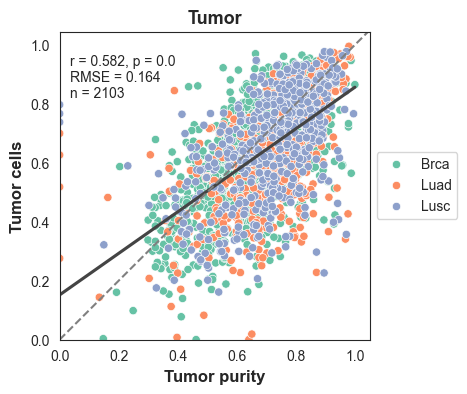

In [38]:
luad_estimations = pd.read_csv("../output/luad_estimations.csv", index_col=0)
luad_estimations['CPE'] = luad_estimations['Tumor cells']

lusc_estimations = pd.read_csv("../output/lusc_estimations.csv", index_col=0)
lusc_estimations['CPE'] = lusc_estimations['Tumor cells']

brca_estimations = pd.read_csv("../output/brca_estimations.csv", index_col=0)
brca_estimations.index = brca_estimations.index.str.replace("-", ".")
brca_estimations['CPE'] = brca_estimations['Cancer Epithelial']

luad_estimations['data'] = 'Luad'
lusc_estimations['data'] = 'Lusc'
brca_estimations['data'] = 'Brca'

all = pd.concat([brca_estimations, luad_estimations, lusc_estimations])

all_m, gld_m = helper.match_dfs(all, df_grouped)

evaluation_all = helper.create_evaluation_df(gld_m.T, all_m.T)

evaluation_all['data'] = list(all['data'])

rsme_all_t, r_all_t, p_all = helper.evaulate_total_df(evaluation_all)

helper.create_scatter_plot_total(evaluation_all, rsme_all_t, p_all, r_all_t, 'Tumor', y_axis_label="Tumor cells", x_axis_label="Tumor purity", hue='data', save_path='../figures/fig4a_all_tumor.pdf', size=(4, 4))

<Axes: title={'center': 'Unknown'}, xlabel='Tumor purity', ylabel='Unknown cells'>

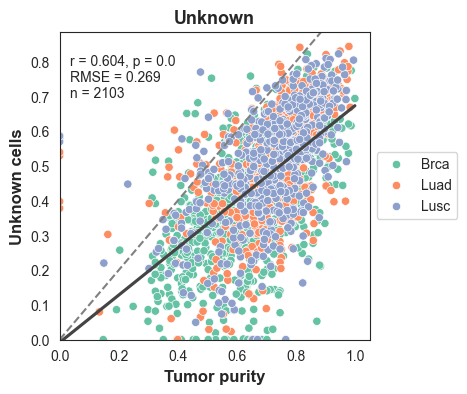

In [40]:
#no tumor
luad_estimations_no_cancer = pd.read_csv("../output/luad_estimations_no_cancer.csv", index_col=0)
luad_estimations_no_cancer['CPE'] = luad_estimations_no_cancer['Unknown']
lusc_estimations_no_cancer = pd.read_csv("../output/lusc_estimations_no_cancer.csv", index_col=0)
lusc_estimations_no_cancer['CPE'] = lusc_estimations_no_cancer['Unknown']
brca_estimations_no_cancer = pd.read_csv("../output/brca_estimations_no_cancer.csv", index_col=0)
brca_estimations_no_cancer.index = brca_estimations_no_cancer.index.str.replace("-", ".")
brca_estimations_no_cancer['CPE'] = brca_estimations_no_cancer['Unknown']

luad_estimations_no_cancer['data'] = 'Luad'
lusc_estimations_no_cancer['data'] = 'Lusc'
brca_estimations_no_cancer['data'] = 'Brca'

all_no_cancer = pd.concat([brca_estimations_no_cancer, luad_estimations_no_cancer, lusc_estimations_no_cancer])
all_no_cancer_m, gld_m_no_cancer = helper.match_dfs(all_no_cancer, df_grouped)
evaluation_all_no_cancer = helper.create_evaluation_df(gld_m_no_cancer.T, all_no_cancer_m.T)
evaluation_all_no_cancer['data'] = list(all_no_cancer['data'])
rsme_all_no_cancer, r_all_no_cancer, p_all_no_cancer = helper.evaulate_total_df(evaluation_all_no_cancer)

helper.create_scatter_plot_total(evaluation_all_no_cancer, rsme_all_no_cancer, p_all_no_cancer, r_all_no_cancer, 'Unknown', y_axis_label="Unknown cells", x_axis_label="Tumor purity", hue='data', save_path='../figures/fig4a_all_unkn.pdf', size=(4, 4))


## 4B

In [43]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Set style
sns.set_style('white')

# Data preparation
values_rsme = [rsme_brca, rsme_luad, rsme_lusc]
values_rsme_t = [rsme_brca_cancer, rsme_luad_cancer, rsme_lusc_cancer]
values_rsme_n = [rsme_brca_no_cancer, rsme_luad_no_cancer, rsme_lusc_no_cancer]

values_corr = [r_brca, r_luad, r_lusc]
values_corr_t = [r_brca_cancer, r_luad_cancer, r_lusc_cancer]
values_corr_n = [r_brca_no_cancer, r_luad_no_cancer, r_lusc_no_cancer]

# Create DataFrame
standard_df = pd.DataFrame({
    'RMSE': values_rsme,
    'Correlation': values_corr,
    'Dataset': ['Brca', 'Luad', 'Lusc'],
    'Condition': ['Tumor+Unkn'] * 3
})

tumor_df = pd.DataFrame({
    'RMSE': values_rsme_t,
    'Correlation': values_corr_t,
    'Dataset': ['Brca', 'Luad', 'Lusc'],
    'Condition': ['Tumor'] * 3
})

unknown_df = pd.DataFrame({
    'RMSE': values_rsme_n,
    'Correlation': values_corr_n,
    'Dataset': ['Brca', 'Luad', 'Lusc'],
    'Condition': ['Unkn'] * 3
})

# Concatenate the DataFrames
df = pd.concat([standard_df, tumor_df, unknown_df])



In [1]:
import seaborn as sns

import matplotlib.pyplot as plt
import pandas as pd

sns.set_theme("notebook")
sns.set_style('ticks')
# Set a color palette
color_palette =  ['#66C2A5','#FC8D62','#8DA0CB']

# Combine the data into a single DataFrame
df_combined = pd.DataFrame({
    'RMSE': values_rsme + values_rsme_t + values_rsme_n,
    'Correlation': values_corr + values_corr_t + values_corr_n,
    'Condition': ['Tumor+Unkn'] * 3 + ['Tumor'] * 3 + ['Unkn'] * 3,
    'Dataset': ['Brca', 'Luad', 'Lusc'] * 3
})

# Create the scatter plot
plt.figure(figsize=(3, 3))
ax = sns.scatterplot(data=df_combined, x='RMSE', y='Correlation', hue='Dataset', style='Condition', s=100, palette=color_palette)
plt.title('RMSE vs Correlation')

# Custom legend with two columns: Dataset and Condition
handles, labels = ax.get_legend_handles_labels()
# The first handle/label is for the title, skip it
handles = handles[1:]
labels = labels[1:]

# Remove duplicate legend entries
plt.legend(list(legend_dict.values()), list(legend_dict.keys()), ncol=2, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

plt.savefig('../figures/fig4b_all_unkn_comparison_scatter.pdf', bbox_inches='tight', dpi=300)
plt.show()


NameError: name 'values_rsme' is not defined

In [1]:
## 4C

In [19]:
unknown_content_results = pd.read_csv("../data/fig4/unknown_content_results.csv", index_col=0)
distinct_fractions = [0.1 , 0.2 , 0.3 , 0.5 , 0.7 , 0.9 , 0.  ]
unknown_content_results = unknown_content_results[unknown_content_results['unknown_fraction'].isin(distinct_fractions)]

# Rename methods to match method_palette capitalization
method_mapping = {
    'autogenes': 'AutoGeneS',
    'bayesprism': 'BayesPrism',
    'bisque': 'Bisque',
    'cibersortx': 'CIBERSORTx',
    'dwls': 'DWLS',
    'music': 'MuSiC',
    'scaden': 'Scaden',
    'scdc': 'SCDC',
    'rectangle': 'Rectangle'
}
unknown_content_results['method'] = unknown_content_results['method'].replace(method_mapping)

In [20]:
from scipy import stats

# Correlation results grouped by celltype, method, replicate, dataset, unknown_fraction
correlation_results = unknown_content_results.groupby(['celltype', 'method', 'replicate', 'dataset', 'unknown_fraction']).apply(
    lambda x: pd.Series({
        'corr': stats.pearsonr(x['true_value'], x['predicted_value'])[0],
        'pval': stats.pearsonr(x['true_value'], x['predicted_value'])[1]
    })
).reset_index()

# Correlation results for all cells grouped by method, replicate, dataset, unknown_fraction
correlation_results_all = unknown_content_results.groupby(['method', 'replicate', 'dataset', 'unknown_fraction']).apply(
    lambda x: pd.Series({
        'corr': stats.pearsonr(x['true_value'], x['predicted_value'])[0],
        'pval': stats.pearsonr(x['true_value'], x['predicted_value'])[1]
    })
).reset_index()
correlation_results_all['celltype'] = 'all-cells'

# Correlation results for all cells grouped by method, dataset, unknown_fraction (no replicate)
cor_results_all = unknown_content_results.groupby(['method', 'dataset', 'unknown_fraction']).apply(
    lambda x: pd.Series({
        'corr': stats.pearsonr(x['true_value'], x['predicted_value'])[0],
        'pval': stats.pearsonr(x['true_value'], x['predicted_value'])[1]
    })
).reset_index()

# RMSE results grouped by celltype, method, replicate, dataset, unknown_fraction
rmse_results = unknown_content_results.groupby(['celltype', 'method', 'replicate', 'dataset', 'unknown_fraction']).apply(
    lambda x: pd.Series({
        'rmse': ((x['true_value'] - x['predicted_value'])**2).mean()**0.5
    })
).reset_index()

# RMSE results for all cells grouped by method, replicate, dataset, unknown_fraction
rmse_results_all = unknown_content_results.groupby(['method', 'replicate', 'dataset', 'unknown_fraction']).apply(
    lambda x: pd.Series({
        'rmse': ((x['true_value'] - x['predicted_value'])**2).mean()**0.5
    })
).reset_index()
rmse_results_all['celltype'] = 'all-cells'

# Combine RMSE results
rmse_results = pd.concat([rmse_results, rmse_results_all], ignore_index=True)

# Combine correlation results
correlation_results = pd.concat([correlation_results, correlation_results_all], ignore_index=True)

/var/folders/8f/k23cncy95sd_km_vcbbc6dn40000gn/T/ipykernel_51359/3453203749.py:6: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  'corr': stats.pearsonr(x['true_value'], x['predicted_value'])[0],
/var/folders/8f/k23cncy95sd_km_vcbbc6dn40000gn/T/ipykernel_51359/3453203749.py:7: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  'pval': stats.pearsonr(x['true_value'], x['predicted_value'])[1]
/var/folders/8f/k23cncy95sd_km_vcbbc6dn40000gn/T/ipykernel_51359/3453203749.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  correlation_results = unknown_content_results.groupby(['celltype', 'method', 'replicate', 

In [21]:
# Summary function (equivalent to R's data_summary)
def data_summary(data, varname, groupnames):
    """
    Calculate mean, sd, and IQR for a variable grouped by specified columns.

    Parameters:
    - data: DataFrame
    - varname: column name to summarize
    - groupnames: list of column names to group by
    """
    summary = data.groupby(groupnames)[varname].agg([
        ('mean', 'mean'),
        ('sd', 'std'),
        ('25%', lambda x: x.quantile(0.25)),
        ('75%', lambda x: x.quantile(0.75))
    ]).reset_index()

    # Rename 'mean' column to the original variable name
    summary = summary.rename(columns={'mean': varname})

    return summary

# Calculate summary statistics for correlation results
correlation_results_summary = data_summary(correlation_results, 'corr', ['celltype', 'method', 'unknown_fraction', 'dataset'])
correlation_summary_all = correlation_results_summary[correlation_results_summary['celltype'] == 'all-cells']

# Calculate summary statistics for RMSE results
rmse_results_summary = data_summary(rmse_results, 'rmse', ['celltype', 'method', 'unknown_fraction', 'dataset'])
rmse_summary_all = rmse_results_summary[rmse_results_summary['celltype'] == 'all-cells']

In [22]:
rmse_summary_all

,celltype,method,unknown_fraction,dataset,rmse,sd,25%,75%
259,all-cells,AutoGeneS,0.0,lambrechts,0.087565,0.003606,0.084398,0.090366
260,all-cells,AutoGeneS,0.1,lambrechts,0.076845,0.003972,0.073764,0.078878
261,all-cells,AutoGeneS,0.2,lambrechts,0.101393,0.008600,0.094553,0.105127
262,all-cells,AutoGeneS,0.3,lambrechts,0.148036,0.022049,0.128231,0.162041
263,all-cells,AutoGeneS,0.5,lambrechts,0.213210,0.022048,0.204522,0.227866
...,...,...,...,...,...,...,...,...
317,all-cells,Scaden,0.2,lambrechts,0.131008,0.002503,0.130740,0.132396
318,all-cells,Scaden,0.3,lambrechts,0.151126,0.006071,0.150407,0.154206
319,all-cells,Scaden,0.5,lambrechts,0.202100,0.003694,0.199711,0.202018
320,all-cells,Scaden,0.7,lambrechts,0.249398,0.005062,0.245835,0.253208


In [23]:
method_palette = {
    "AutoGeneS": "#66C2A5",
    "BayesPrism": "#FC8D62",
    "Bisque": "#8DA0CB",
    "CIBERSORTx": "#E78AC3",
    "DWLS": "#A6D854",
    "MuSiC": "#FFD92F",
    "Scaden": "#E5C494",
    "SCDC": "#B3B3B3",
    "Rectangle": "#000000"
}

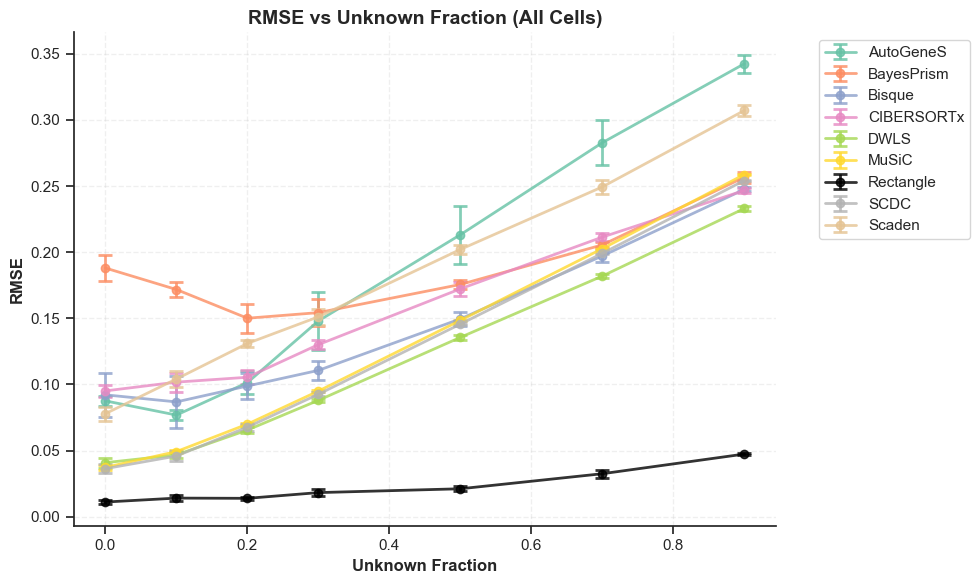

In [28]:
# Plot RMSE summary for all cells
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme("notebook")
sns.set_style('ticks')

fig, ax = plt.subplots(figsize=(10, 6))

# Plot with error bars (using standard deviation)
for method in rmse_summary_all['method'].unique():
    method_data = rmse_summary_all[rmse_summary_all['method'] == method]

    # Sort by unknown_fraction for proper line plotting
    method_data = method_data.sort_values('unknown_fraction')

    x = method_data['unknown_fraction']
    y = method_data['rmse']
    yerr = method_data['sd']

    color = method_palette.get(method, '#000000')
    ax.errorbar(x, y, yerr=yerr, label=method, marker='o', capsize=5,
                capthick=2, linewidth=2, markersize=6, color=color, alpha=0.8)

ax.set_xlabel('Unknown Fraction', fontsize=12, fontweight='bold')
ax.set_ylabel('RMSE', fontsize=12, fontweight='bold')
ax.set_title('RMSE vs Unknown Fraction (All Cells)', fontsize=14, fontweight='bold')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True)
ax.grid(True, alpha=0.3, linestyle='--')
sns.despine()

plt.tight_layout()
plt.savefig('../figures/fig4c_rmse_summary_all.pdf', bbox_inches='tight', dpi=300)
plt.show()


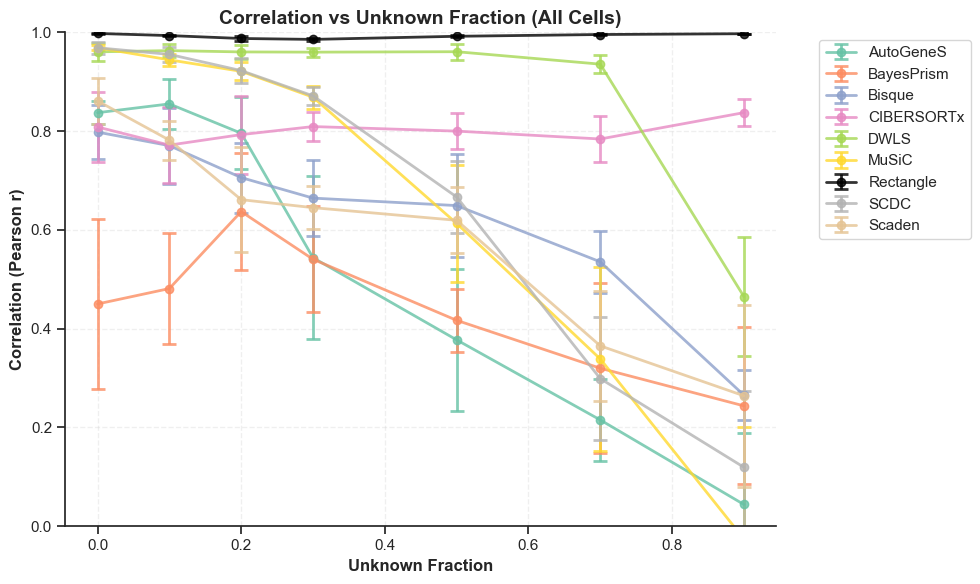

In [29]:
# Plot Correlation summary for all cells
fig, ax = plt.subplots(figsize=(10, 6))

# Plot with error bars (using standard deviation)
for method in correlation_summary_all['method'].unique():
    method_data = correlation_summary_all[correlation_summary_all['method'] == method]

    # Sort by unknown_fraction for proper line plotting
    method_data = method_data.sort_values('unknown_fraction')

    x = method_data['unknown_fraction']
    y = method_data['corr']
    yerr = method_data['sd']

    color = method_palette.get(method, '#000000')
    ax.errorbar(x, y, yerr=yerr, label=method, marker='o', capsize=5,
                capthick=2, linewidth=2, markersize=6, color=color, alpha=0.8)

ax.set_xlabel('Unknown Fraction', fontsize=12, fontweight='bold')
ax.set_ylabel('Correlation (Pearson r)', fontsize=12, fontweight='bold')
ax.set_title('Correlation vs Unknown Fraction (All Cells)', fontsize=14, fontweight='bold')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_ylim([0, 1])
sns.despine()

plt.tight_layout()
plt.savefig('../figures/fig4c_correlation_summary_all.pdf', bbox_inches='tight', dpi=300)
plt.show()
